In [7]:
import pandas as pd
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import plotly.express as px
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from mpl_toolkits.mplot3d import Axes3D
from collections import Counter

In [8]:
gene_disease_matrix = pd.read_csv('/home/yolanda/tblab/yolanda/GLOWgenes/panelAPP/analysis/glowmatrix.tsv',sep = '\t') 
gene_disease_matrix

,SYMBOL,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,...,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,COVID-19_research_GA,Viral_resistance_GA
0,FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,...,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,73.0,15719.0
1,FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,...,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,0.0,4246.0
2,POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,...,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,132.0,13009.0
3,FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,...,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,17.0,13652.0
4,XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,...,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,62.0,3125.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24752,MTSS1L,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24753,C2orf71,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24754,FAM57B,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
24755,FAM92A,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
gene_disease_matrix=gene_disease_matrix.iloc[:, :-2] # quitamos los paneles de Viral Research (los 2 últimos)
gene_disease_matrix

Cargamos la matriz del ranking de GLOWgenes con cada panel de panelApp
Obtenemos, de cada panel, su valor más bajo de GLOWgene para darle a los NA ese ranking (para que los NA tengan el valor del último gen rankeado + 1) 

In [4]:
max_valuedisease=gene_disease_matrix.set_index("SYMBOL").max(axis=0)
max_valuedisease.head()

Adult_solid_tumours_cancer_susceptibility_GA               22245.0
Childhood_solid_tumours_cancer_susceptibility_GA           22673.0
Colorectal_cancer_pertinent_cancer_susceptibility_GA       19556.0
Haematological_malignancies_cancer_susceptibility_GA       22663.0
Head_and_neck_cancer_pertinent_cancer_susceptibility_GA    22725.0
dtype: float64

In [5]:
gene_disease_matrix = gene_disease_matrix.set_index("SYMBOL").fillna(gene_disease_matrix.set_index("SYMBOL").max()+1) # establezco NA como el máximo de su panel.
gene_disease_matrix

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,GI_tract_tumours_GA,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,6733.0,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,68.0,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,522.0,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2074.0,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,94.0,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,19732.0,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0
C2orf71,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,19732.0,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0
FAM57B,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,19732.0,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0


In [6]:
data_np = gene_disease_matrix.to_numpy(copy=True)

Transformamos el dataframe con los genes y las enfermedades en una matriz de numpy.

# PCA

In [7]:
pca = PCA(n_components=3)  # Reduce to 2 components for visualization purposes
pca.fit(data_np)

# Explained variance
explained_variance = pca.explained_variance_
print("Explained Variance:", explained_variance)

# Explained variance ratio
explained_variance_ratio = pca.explained_variance_ratio_
print("Explained Variance Ratio:", explained_variance_ratio)
explained_variance = explained_variance_ratio

# PCA components (eigenvectors)
components = pca.components_
#print("PCA Components:\n", components)

# Singular values
singular_values = pca.singular_values_
#print("Singular Values:", singular_values)


reduced_matrix = pca.fit_transform(data_np)

Explained Variance: [6.49483774e+09 2.90836267e+08 2.43195196e+08]
Explained Variance Ratio: [0.70749179 0.0316812  0.02649159]


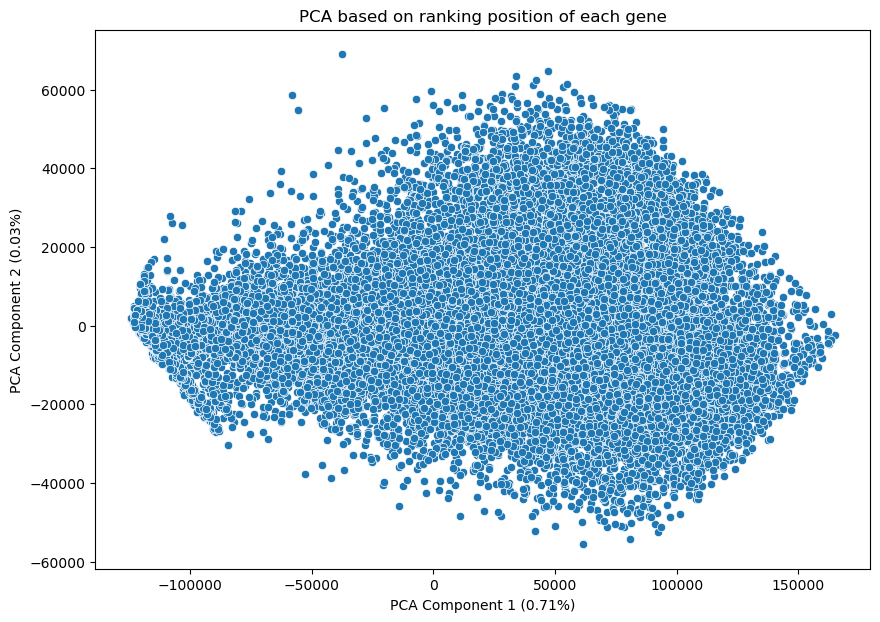

In [8]:
# Visualization
plt.figure(figsize=(10, 7))
fig = sns.scatterplot(x=reduced_matrix[:, 0], y=reduced_matrix[:, 1])
plt.title('PCA based on ranking position of each gene')
plt.xlabel('PCA Component 1 (' + str(round(explained_variance_ratio[0], 2)) +"%)")
plt.ylabel('PCA Component 2 (' + str(round(explained_variance_ratio[1], 2)) +"%)")
#fig.invert_xaxis() 
#fig.invert_yaxis() 
plt.show()

## t-SNE

In [16]:
#https://www.datacamp.com/tutorial/introduction-t-sne
tsne = TSNE(n_components=2, random_state=42)
tsne_results = tsne.fit_transform(data_np)
tsne.kl_divergence_

2.3840532302856445

In [10]:
import numpy as np
'''
#perplexity = np.arange(5, 55, 5)
perplexity = np.arange(100, 120, 5)
divergence = []

for i in perplexity:
    model = TSNE(n_components=2, init="pca", perplexity=i)
    reduced = model.fit_transform(data_np)
    divergence.append(model.kl_divergence_)
fig = px.line(x=perplexity, y=divergence, markers=True)
fig.update_layout(xaxis_title="Perplexity Values", yaxis_title="Divergence")
fig.update_traces(line_color="red", line_width=1)
fig.show()
'''

'\n#perplexity = np.arange(5, 55, 5)\nperplexity = np.arange(100, 120, 5)\ndivergence = []\n\nfor i in perplexity:\n    model = TSNE(n_components=2, init="pca", perplexity=i)\n    reduced = model.fit_transform(data_np)\n    divergence.append(model.kl_divergence_)\nfig = px.line(x=perplexity, y=divergence, markers=True)\nfig.update_layout(xaxis_title="Perplexity Values", yaxis_title="Divergence")\nfig.update_traces(line_color="red", line_width=1)\nfig.show()\n'

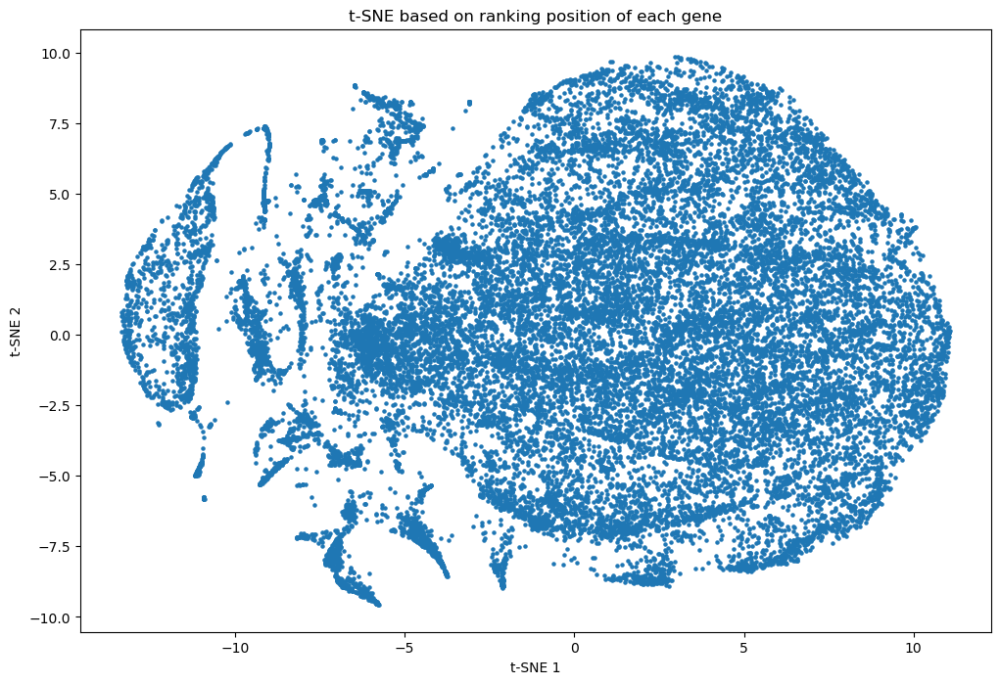

In [17]:
# Fit and transform the data using t-SNE
tsne = TSNE(n_components=2, perplexity=30, n_iter=300)
tsne_results = tsne.fit_transform(data_np)

# Plot t-SNE results
plt.figure(figsize=(12, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], s=5)
plt.title('t-SNE based on ranking position of each gene')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

In [12]:
tsne.kl_divergence_

3.7436718940734863

## Clustering (K-Means)

Vamos a hacer el clústering con K-means. Necesitamos saber el número de clusters a utilizar. Usamos el método del codo. 

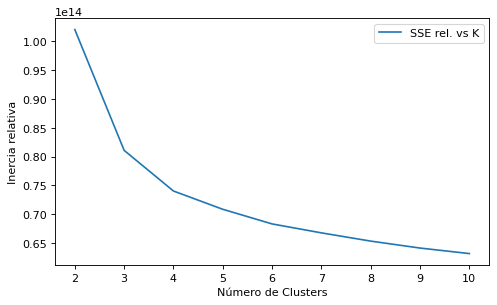

In [13]:
from sklearn.cluster import KMeans
import sklearn.metrics as metrics
# Configuración del modelo de K-Means con un número inicial de clusters (n_clusters) igual a 1
km = KMeans(n_clusters=1, init='k-means++', n_init='auto', max_iter=300, tol=1e-04, random_state=0)
# Ajusta el modelo a los datos estandarizados
km.fit(data_np)
# Calcula la inercia total del modelo con un solo clúster
tss=km.inertia_
# Lista para almacenar las inercias relativas para diferentes números de clusters
distortions = []
# Itera sobre diferentes números de clusters y ajusta el modelo K-Means
for i in range(2, 11):
    km = KMeans(n_clusters=i, init='k-means++', n_init='auto', max_iter=300, tol=1e-04)
    km.fit(data_np)
    #distortions.append(km.inertia_/tss)
    distortions.append(km.inertia_)
    
plt.figure(figsize=(7, 4), dpi=80)
plt.plot(range(2,11), distortions, label="SSE rel. vs K")
plt.xlabel("Número de Clusters")
plt.ylabel("Inercia relativa")
plt.legend(loc='upper right')
plt.show()

Seleccionamos 4 - 5 clusters y vemos cual nos da mejor resultado. 

### 4 clusters

In [18]:
# Clustering
kmeans = KMeans(n_clusters=4)  # Number of clusters is a hyperparameter you can tune
gene_clusters = kmeans.fit_predict(data_np)
# kmeans debería hacerlo con la matriz "normal"? o con la matriz que te da la PCA en 2d? Los clusters salen casi igual.
# también he probado con la matriz sin ordenar y también sale muy parecido. 
# gene_clusters = kmeans.fit_predict(gene_disease_matrix.to_numpy())

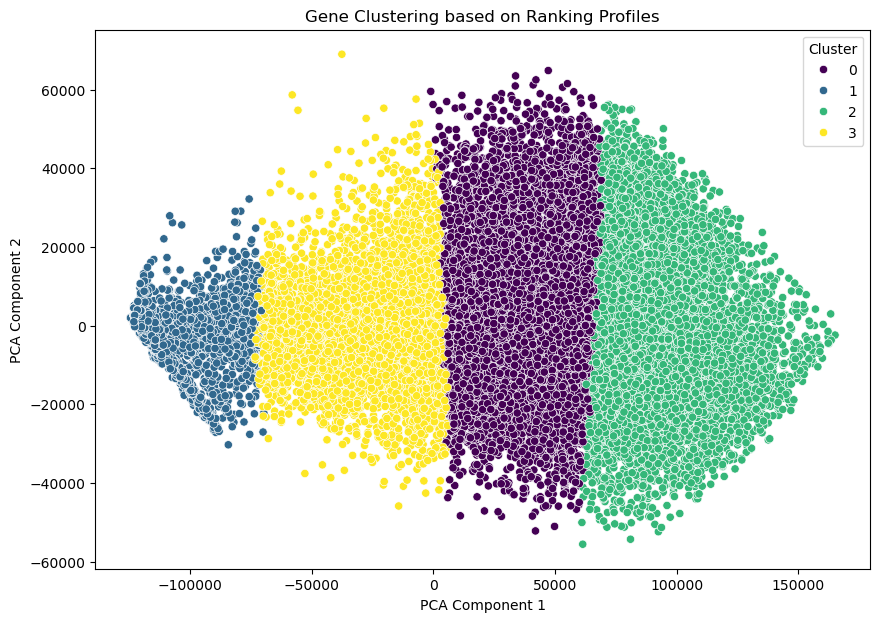

In [19]:
# Visualization
plt.figure(figsize=(10, 7))
fig = sns.scatterplot(x=reduced_matrix[:, 0], y=reduced_matrix[:, 1], hue=gene_clusters, palette='viridis')
plt.title('Gene Clustering based on Ranking Profiles')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
#fig.invert_xaxis() 
#fig.invert_yaxis() 
plt.show()

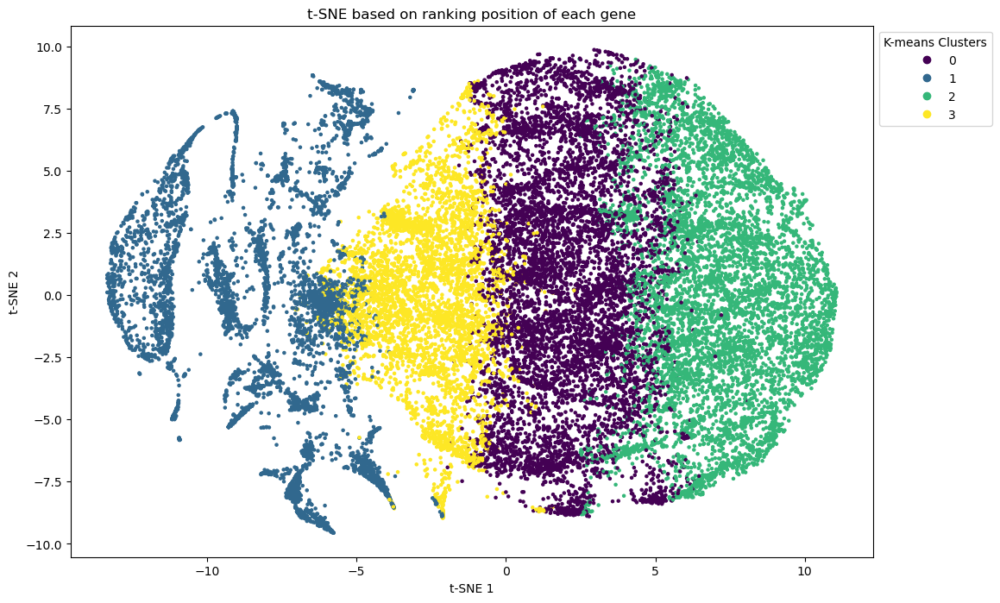

In [20]:
# Plot t-SNE results
plt.figure(figsize=(12, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=gene_clusters, s=5)
plt.legend(handles=scatter.legend_elements()[0], labels=set(gene_clusters), title="K-means Clusters", bbox_to_anchor=(1.0, 1), loc='upper left')
plt.title('t-SNE based on ranking position of each gene')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

In [21]:
print(Counter(gene_clusters))

Counter({0: 7395, 1: 6469, 2: 6298, 3: 4595})


In [22]:
gene_disease_matrix['Cluster'] = gene_clusters
gene_disease_matrix.head()

/tmp/ipykernel_1421517/2580937037.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  gene_disease_matrix['Cluster'] = gene_clusters


,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,3
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,2
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,2
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,0
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,2


In [23]:
cluster = 0
data_np[gene_clusters == cluster].shape

(7395, 209)

In [24]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[10709.72727273  9280.36363636  8677.77511962 ... 11044.57416268
  8094.32535885 10311.88995215]


In [25]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 0: 9374.74
Std del ranking de los genes del cluster 0: 4510.0
Mediana del ranking de los genes del cluster 0: 9902.0
Percentil 20 del ranking de los genes del cluster 0: 4887.0
Percentil 40 del ranking de los genes del cluster 0: 8422.0
Percentil 80 del ranking de los genes del cluster 0: 13682.0


In [26]:
cluster = 3
data_np[gene_clusters == cluster].shape

(4595, 209)

In [27]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[12751.70334928 12275.86124402 13227.30143541 ... 15920.23923445
 14510.8708134  13764.00956938]


In [28]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 3: 13897.99
Std del ranking de los genes del cluster 3: 4600.75
Mediana del ranking de los genes del cluster 3: 15521.0
Percentil 20 del ranking de los genes del cluster 3: 10552.0
Percentil 40 del ranking de los genes del cluster 3: 14503.0
Percentil 80 del ranking de los genes del cluster 3: 17530.0


In [29]:
cluster = 2

In [30]:
data_np[gene_clusters == cluster].shape

(6298, 209)

In [31]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[3911.20574163 6938.99043062 4549.40669856 ... 2147.73205742 3980.49760766
 5540.78947368]


In [32]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 2: 5420.84
Std del ranking de los genes del cluster 2: 3731.96
Mediana del ranking de los genes del cluster 2: 4931.0
Percentil 20 del ranking de los genes del cluster 2: 1753.0
Percentil 40 del ranking de los genes del cluster 2: 3803.0
Percentil 80 del ranking de los genes del cluster 2: 8904.0


In [33]:
cluster = 1
data_np[gene_clusters == cluster].shape

(6469, 209)

In [34]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[16928.25837321 18316.5215311  18023.68421053 ... 20401.55980861
 20401.33014354 20417.11483254]


In [35]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 1: 19743.88
Std del ranking de los genes del cluster 1: 1987.25
Mediana del ranking de los genes del cluster 1: 19651.0
Percentil 20 del ranking de los genes del cluster 1: 19363.0
Percentil 40 del ranking de los genes del cluster 1: 19552.0
Percentil 80 del ranking de los genes del cluster 1: 20923.0


In [36]:
cluster_stats_full = gene_disease_matrix.groupby('Cluster').agg(['mean', 'min', 'max'])
cluster_stats_full.T

Cluster                                                           0  \
Adult_solid_tumours_cancer_susceptibility_GA     mean  10027.678026   
                                                 min       0.000000   
                                                 max   19398.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean  10213.620554   
                                                 min       4.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min       0.000000   
                                                 max   17848.000000   
Neurofibromatosis_Type_1_GA                      mean   9641.530764   
                                                 min       2.000000   
                                                 max   18529.000000   

Cluster                                                           1  \
Adult_solid_tumours_cancer_susceptibility_GA     mean  20258.244706   
                                                 min    1121.000000   
                                                 max   22246.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean  20085.817901   
                                                 min    2278.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min     119.000000   
                                                 max   19737.000000   
Neurofibromatosis_Type_1_GA                      mean  20595.977895   
                                                 min    1910.000000   
                                                 max   22228.000000   

Cluster                                                           2  \
Adult_solid_tumours_cancer_susceptibility_GA     mean   4324.524929   
                                                 min       0.000000   
                                                 max   16487.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean   4726.779771   
                                                 min       0.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min       0.000000   
                                                 max   16432.000000   
Neurofibromatosis_Type_1_GA                      mean   5730.844236   
                                                 min       0.000000   
                                                 max   17614.000000   

Cluster                                                           3  
Adult_solid_tumours_cancer_susceptibility_GA     mean  14939.578890  
                                                 min       0.000000  
                                                 max   21931.000000  
Childhood_solid_tumours_cancer_susceptibility_GA mean  14615.378020  
                                                 min      25.000000  
...                                                             ...  
Multiple_endocrine_tumours_GA                    min      18.000000  
                                                 max   19737.000000  
Neurofibromatosis_Type_1_GA                      mean  13506.514037  
                                                 min       4.000000  
                                                 max   21933.000000  

[627 rows x 4 columns]

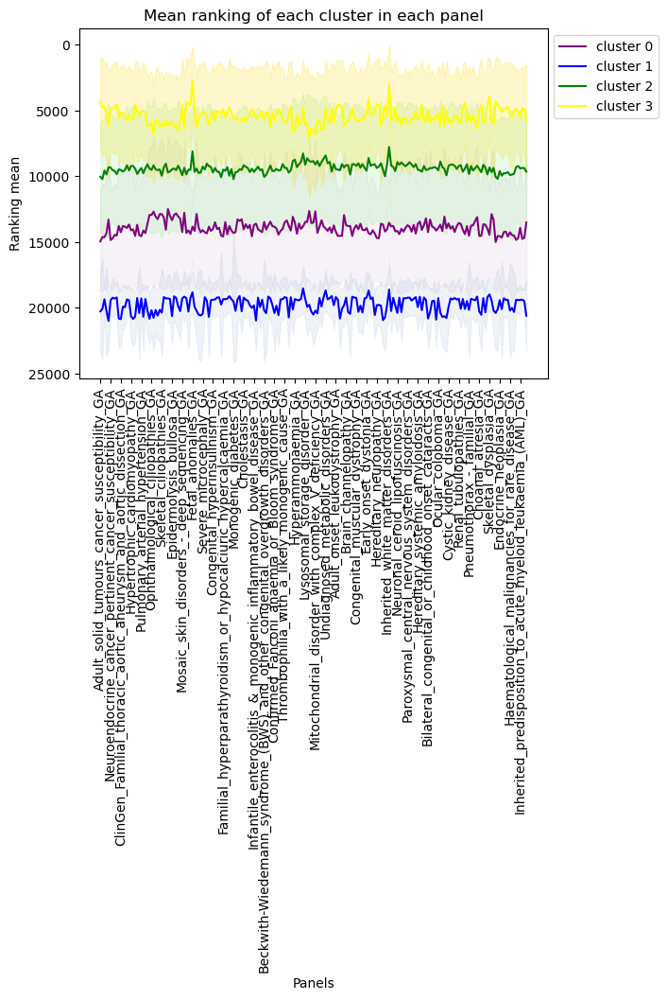

In [33]:
mean_cluster = gene_disease_matrix.groupby('Cluster').agg(['mean'])
max_cluster = gene_disease_matrix.groupby('Cluster').agg(['max'])
min_cluster = gene_disease_matrix.groupby('Cluster').agg(['min'])
std_cluster = gene_disease_matrix.groupby('Cluster').agg(['std'])

fig = plt.subplot()

#plt.errorbar(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[0]), list(std_cluster.iloc[0]), color='thistle', )
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[0]), label='cluster 0', color='purple')
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[1]), label='cluster 1', color='blue' )
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[2]), label='cluster 2', color='green')
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[3]), label='cluster 3', color='yellow' )
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[0])) - np.array(list(std_cluster.iloc[0])), 
                 np.array(list(mean_cluster.iloc[0])) + np.array(list(std_cluster.iloc[0])),
                 color='thistle', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[1])) - np.array(list(std_cluster.iloc[1])), 
                 np.array(list(mean_cluster.iloc[1])) + np.array(list(std_cluster.iloc[1])),
                 color='lightsteelblue', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[2])) - np.array(list(std_cluster.iloc[2])), 
                 np.array(list(mean_cluster.iloc[2])) + np.array(list(std_cluster.iloc[2])),
                 color='lightgreen', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[3])) - np.array(list(std_cluster.iloc[3])), 
                 np.array(list(mean_cluster.iloc[3])) + np.array(list(std_cluster.iloc[3])),
                 color='gold', alpha=0.2)

fig.set_title("Mean ranking of each cluster in each panel")

#plt.xticks([])
plt.xticks(rotation = 90)
plt.xticks(np.take(gene_disease_matrix.columns[:-1], np.arange(0,209,step=5)))
plt.legend(bbox_to_anchor=(1.25, 1.0), loc='upper right')
plt.xlabel("Panels")
plt.ylabel("Ranking mean")
fig.invert_yaxis() 

In [34]:
gene_disease_matrix

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,0
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,3
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,3
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,2
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
C2orf71,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
FAM57B,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1


### 5 clusters

In [37]:
# Clustering
kmeans = KMeans(n_clusters=5)  # Number of clusters is a hyperparameter you can tune
gene_clusters = kmeans.fit_predict(data_np)
# kmeans debería hacerlo con la matriz "normal"? o con la matriz que te da la PCA en 2d? Los clusters salen casi igual.
# también he probado con la matriz sin ordenar y también sale muy parecido. 
# gene_clusters = kmeans.fit_predict(gene_disease_matrix.to_numpy())

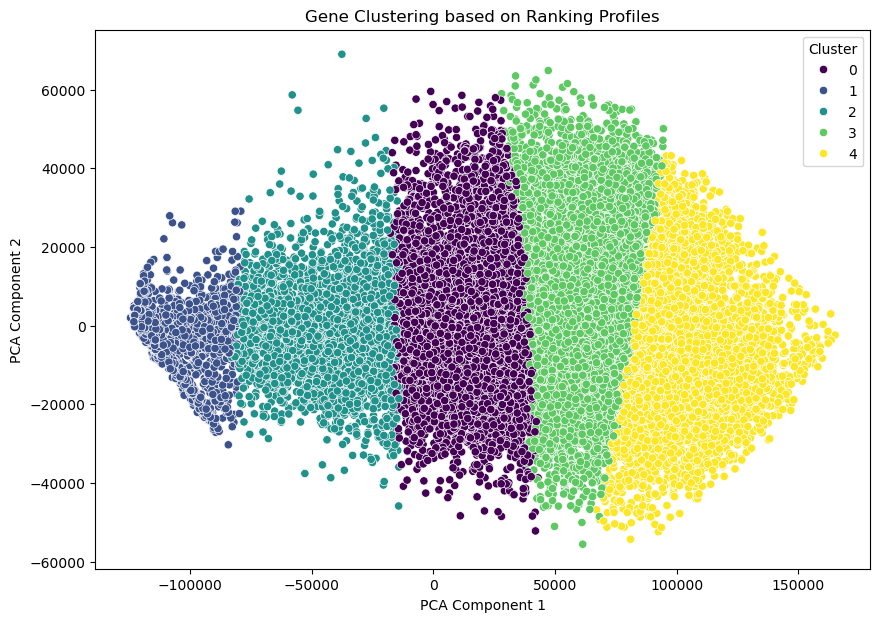

In [38]:
# Visualization
plt.figure(figsize=(10, 7))
fig = sns.scatterplot(x=reduced_matrix[:, 0], y=reduced_matrix[:, 1], hue=gene_clusters, palette='viridis')
plt.title('Gene Clustering based on Ranking Profiles')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.legend(title='Cluster')
#fig.invert_xaxis() 
#fig.invert_yaxis() 
plt.show()

In [39]:
tsne_results
tsne = pd.DataFrame(tsne_results)
#tsne.to_csv('/home/yolanda/tblab/yolanda/GLOWgenes/panelAPP/analysis/data_exploration/tsne.tsv', sep="\t")

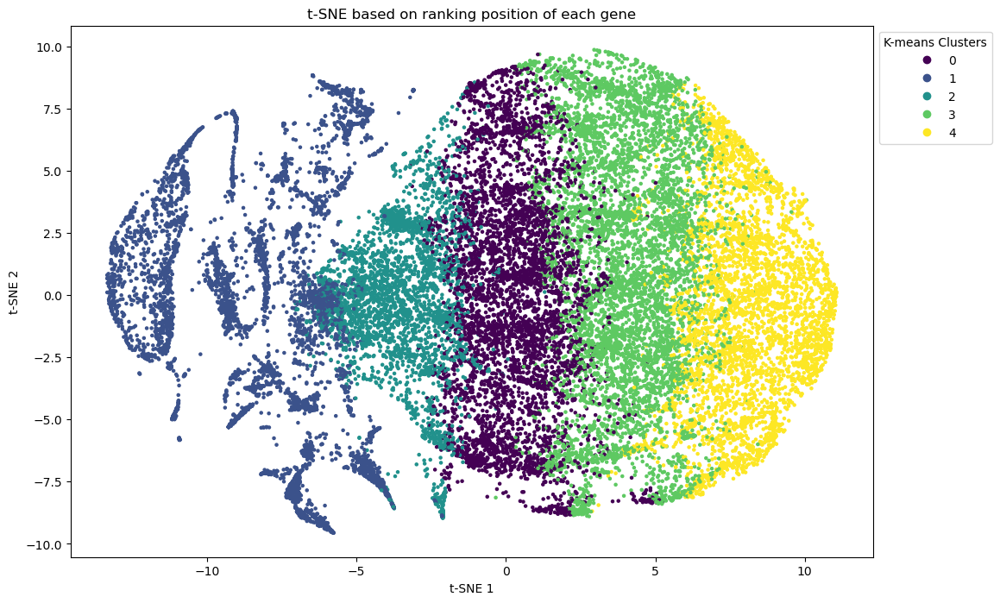

In [40]:
# Plot t-SNE results
plt.figure(figsize=(12, 8))
scatter = plt.scatter(tsne_results[:, 0], tsne_results[:, 1], c=gene_clusters, s=5)
plt.title('t-SNE based on ranking position of each gene')
plt.legend(handles=scatter.legend_elements()[0], labels=set(gene_clusters), title="K-means Clusters", bbox_to_anchor=(1.0, 1), loc='upper left')
plt.xlabel('t-SNE 1')
plt.ylabel('t-SNE 2')
plt.show()

In [41]:
print(Counter(gene_clusters))

Counter({1: 6135, 3: 6025, 0: 5154, 4: 4041, 2: 3402})


In [42]:
gene_disease_matrix['Cluster'] = gene_clusters
gene_disease_matrix.head()

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,0
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,4
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,3
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,0
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,4


In [43]:
cluster = 1
data_np[gene_clusters == cluster].shape

(6135, 209)

In [44]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[18316.5215311  18023.68421053 19280.40191388 ... 20401.55980861
 20401.33014354 20417.11483254]


In [45]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 1: 19884.72
Std del ranking de los genes del cluster 1: 1766.01
Mediana del ranking de los genes del cluster 1: 19673.0
Percentil 20 del ranking de los genes del cluster 1: 19455.0
Percentil 40 del ranking de los genes del cluster 1: 19570.0
Percentil 80 del ranking de los genes del cluster 1: 20958.0


In [62]:
cluster = 4
data_np[gene_clusters == cluster].shape

(4041, 209)

In [63]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[3911.20574163 4549.40669856 6501.28229665 ... 2147.73205742 3980.49760766
 5540.78947368]


In [64]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 4: 4688.93
Std del ranking de los genes del cluster 4: 3434.37
Mediana del ranking de los genes del cluster 4: 4076.0
Percentil 20 del ranking de los genes del cluster 4: 1401.0
Percentil 40 del ranking de los genes del cluster 4: 3096.0
Percentil 80 del ranking de los genes del cluster 4: 7791.0


In [53]:
cluster = 3
data_np[gene_clusters == cluster].shape

(6025, 209)

In [54]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[6938.99043062 9280.36363636 6951.80382775 ... 7098.74641148 6438.81339713
 8094.32535885]


In [55]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 3: 7755.88
Std del ranking de los genes del cluster 3: 4206.21
Mediana del ranking de los genes del cluster 3: 7849.0
Percentil 20 del ranking de los genes del cluster 3: 3576.0
Percentil 40 del ranking de los genes del cluster 3: 6501.0
Percentil 80 del ranking de los genes del cluster 3: 11773.0


In [56]:
cluster = 0
data_np[gene_clusters == cluster].shape

(5154, 209)

In [57]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[12751.70334928 10709.72727273  9586.41626794 ... 12384.48803828
 12268.96172249 10311.88995215]


In [58]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 0: 10964.19
Std del ranking de los genes del cluster 0: 4599.93
Mediana del ranking de los genes del cluster 0: 12007.0
Percentil 20 del ranking de los genes del cluster 0: 6540.0
Percentil 40 del ranking de los genes del cluster 0: 10577.0
Percentil 80 del ranking de los genes del cluster 0: 15173.0


In [59]:
cluster = 2
data_np[gene_clusters == cluster].shape

(3402, 209)

In [60]:
print("Media del ranking por gen en el cluster 0")
print(data_np[gene_clusters == cluster].mean(axis = 1)) # media por gen

Media del ranking por gen en el cluster 0
[13227.30143541 16928.25837321 15674.36363636 ... 14510.8708134
 17138.30143541 13764.00956938]


In [61]:
print("Media del ranking de los genes del cluster " + str(cluster) + ": "  + str(round(data_np[gene_clusters == cluster].mean(),2))) # media del cluster
print("Std del ranking de los genes del cluster " + str(cluster) + ": " + str(round(data_np[gene_clusters == cluster].std(),2)))
print("Mediana del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.median(data_np[gene_clusters == cluster]), 2)))

print("Percentil 20 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 20),2)))
print("Percentil 40 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 40),2)))
print("Percentil 80 del ranking de los genes del cluster " + str(cluster) + ": " + str(round(np.percentile(data_np[gene_clusters == cluster], 80),2)))

Media del ranking de los genes del cluster 2: 14953.48
Std del ranking de los genes del cluster 2: 4385.09
Mediana del ranking de los genes del cluster 2: 16583.0
Percentil 20 del ranking de los genes del cluster 2: 12578.0
Percentil 40 del ranking de los genes del cluster 2: 15836.0
Percentil 80 del ranking de los genes del cluster 2: 18074.0


In [65]:
cluster_stats_full = gene_disease_matrix.groupby('Cluster').agg(['mean', 'min', 'max'])
cluster_stats_full.T

Cluster                                                           0  \
Adult_solid_tumours_cancer_susceptibility_GA     mean  12022.876407   
                                                 min       0.000000   
                                                 max   19565.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean  11936.071789   
                                                 min       4.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min       0.000000   
                                                 max   18437.000000   
Neurofibromatosis_Type_1_GA                      mean  11066.808886   
                                                 min       2.000000   
                                                 max   19044.000000   

Cluster                                                           1  \
Adult_solid_tumours_cancer_susceptibility_GA     mean  20383.245151   
                                                 min    3020.000000   
                                                 max   22246.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean  20217.898778   
                                                 min    2278.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min     418.000000   
                                                 max   19737.000000   
Neurofibromatosis_Type_1_GA                      mean  20773.675795   
                                                 min    1910.000000   
                                                 max   22228.000000   

Cluster                                                           2  \
Adult_solid_tumours_cancer_susceptibility_GA     mean  15824.530276   
                                                 min       0.000000   
                                                 max   22116.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean  15487.753968   
                                                 min     255.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min      22.000000   
                                                 max   19737.000000   
Neurofibromatosis_Type_1_GA                      mean  14475.225162   
                                                 min     206.000000   
                                                 max   21933.000000   

Cluster                                                           3  \
Adult_solid_tumours_cancer_susceptibility_GA     mean   7943.618257   
                                                 min       0.000000   
                                                 max   18244.000000   
Childhood_solid_tumours_cancer_susceptibility_GA mean   8389.120000   
                                                 min       0.000000   
...                                                             ...   
Multiple_endocrine_tumours_GA                    min       0.000000   
                                                 max   17431.000000   
Neurofibromatosis_Type_1_GA                      mean   8257.026888   
                                                 min       0.000000   
                                                 max   18101.000000   

Cluster                                                           4  
Adult_solid_tumours_cancer_susceptibility_GA     mean   3062.613462  
                                                 min       0.000000  
                                                 max   14262.000000  
Childhood_solid_tumours_cancer_susceptibility_GA mean   3366.169512  
                                                 min       0.000000  
...                                                             ...  
Multiple_endocrine_tumours_GA                    min       0.000000  
                            

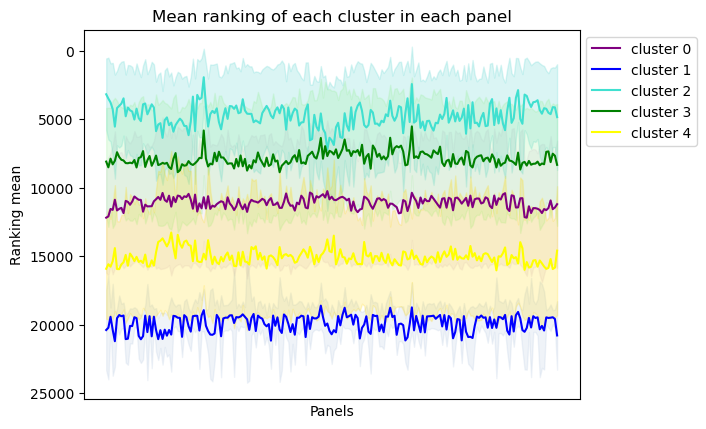

In [57]:
mean_cluster = gene_disease_matrix.groupby('Cluster').agg(['mean'])
max_cluster = gene_disease_matrix.groupby('Cluster').agg(['max'])
min_cluster = gene_disease_matrix.groupby('Cluster').agg(['min'])
std_cluster = gene_disease_matrix.groupby('Cluster').agg(['std'])
sem_cluster = gene_disease_matrix.groupby('Cluster').agg(['sem'])

fig = plt.subplot()

#plt.errorbar(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[0]), list(std_cluster.iloc[0]), color='thistle', )
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[0]), label='cluster 0', color='purple')
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[1]), label='cluster 1', color='blue' )
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[2]), label='cluster 2', color='turquoise')
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[3]), label='cluster 3', color='green' )
plt.plot(list(gene_disease_matrix.columns[:-1]), list(mean_cluster.iloc[4]), label='cluster 4', color='yellow' )

plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[0])) - np.array(list(std_cluster.iloc[0])), 
                 np.array(list(mean_cluster.iloc[0])) + np.array(list(std_cluster.iloc[0])),
                 color='thistle', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[1])) - np.array(list(std_cluster.iloc[1])), 
                 np.array(list(mean_cluster.iloc[1])) + np.array(list(std_cluster.iloc[1])),
                 color='lightsteelblue', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[2])) - np.array(list(std_cluster.iloc[2])), 
                 np.array(list(mean_cluster.iloc[2])) + np.array(list(std_cluster.iloc[2])),
                 color='mediumturquoise', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[3])) - np.array(list(std_cluster.iloc[3])), 
                 np.array(list(mean_cluster.iloc[3])) + np.array(list(std_cluster.iloc[3])),
                 color='lightgreen', alpha=0.2)
plt.fill_between(list(gene_disease_matrix.columns[:-1]), np.array(list(mean_cluster.iloc[4])) - np.array(list(std_cluster.iloc[4])), 
                 np.array(list(mean_cluster.iloc[4])) + np.array(list(std_cluster.iloc[4])),
                 color='gold', alpha=0.2)

fig.set_title("Mean ranking of each cluster in each panel")

plt.xticks([])
#plt.xticks(rotation = 90)
#plt.xticks(np.take(gene_disease_matrix.columns[:-1], np.arange(0,211,step=5)))
plt.legend(bbox_to_anchor=(1.25, 1.0), loc='upper right')
plt.xlabel("Panels")
plt.ylabel("Ranking mean")
fig.invert_yaxis() 

In [58]:
gene_disease_matrix

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,0
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,2
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,3
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,0
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
C2orf71,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
FAM57B,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1


In [66]:
#gene_disease_matrix.to_csv('/home/yolanda/tblab/yolanda/GLOWgenes/panelAPP/analysis/data_exploration/glow_matrix_clustered_no_NA.tsv', sep="\t")

In [10]:
# Clustering
kmeans = KMeans(n_clusters=7)  # Number of clusters is a hyperparameter you can tune
gene_clusters = kmeans.fit_predict(data_np)
# kmeans debería hacerlo con la matriz "normal"? o con la matriz que te da la PCA en 2d? Los clusters salen casi igual.
# también he probado con la matriz sin ordenar y también sale muy parecido. 
# gene_clusters = kmeans.fit_predict(gene_disease_matrix.to_numpy())

print(Counter(gene_clusters))



Counter({1: 6094, 5: 3566, 2: 3292, 0: 3273, 3: 3158, 6: 2838, 4: 2536})


In [12]:
gene_disease_matrix['Cluster'] = gene_clusters
gene_disease_matrix.head()


#gene_disease_matrix.to_csv('/home/yolanda/tblab/yolanda/GLOWgenes/panelAPP/analysis/data_exploration/glow_matrix_clustered_no_NA_7_clusters.tsv', sep="\t")

# Stats

## %Top

Consideramos que el top es el 5% de las primeras posiciones. Si hay 20000 posiciones, serán en la posición 1000. No vamos a tener en cuenta los ceros (las veces que el gen es input). 

In [67]:
threshold_top=0.05

In [68]:
gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].max(axis=0)

Adult_solid_tumours_cancer_susceptibility_GA                      22246.0
Childhood_solid_tumours_cancer_susceptibility_GA                  22674.0
Colorectal_cancer_pertinent_cancer_susceptibility_GA              19557.0
Haematological_malignancies_cancer_susceptibility_GA              22664.0
Head_and_neck_cancer_pertinent_cancer_susceptibility_GA           22726.0
                                                                   ...   
Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA    19655.0
Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA      19688.0
Inherited_renal_cancer_GA                                         19573.0
Multiple_endocrine_tumours_GA                                     19737.0
Neurofibromatosis_Type_1_GA                                       22228.0
Length: 209, dtype: float64

In [69]:
max_valuedisease=gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].max(axis=0)
division = [x*threshold_top for x in list(max_valuedisease)] 

In [70]:
max_valuedisease = pd.DataFrame(max_valuedisease)
max_valuedisease["top_ranking"] = division

In [71]:
max_valuedisease.T.iloc[1:]

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,GI_tract_tumours_GA,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA
top_ranking,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4


In [73]:
comparison_df = pd.DataFrame([division] * gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].shape[0], columns=max_valuedisease.index)
comparison_df.index = gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].index
comparison_df # creamos este dataframe con el valor máximo del %top. Ahora compararemos nuestra tabla con esta (¿la posición 0,0 de glowmatrix es menor que la posición 0.0 de comparation_df?). Así calculamos el % de top. 

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,GI_tract_tumours_GA,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
FANCM,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
POT1,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
FAAP100,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
XRCC3,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
C2orf71,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4
FAM57B,1112.3,1133.7,977.85,1133.2,1136.3,983.05,978.5,977.2,976.3,1113.5,...,986.6,1137.0,1112.8,1112.8,978.95,982.75,984.4,978.65,986.85,1111.4


In [74]:
gene_disease_matrix.head()

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,1.0,25.0,5773.0,20.0,4.0,13424.0,5967.0,8414.0,163.0,15627.0,...,13.0,564.0,493.0,13937.0,14695.0,9970.0,11996.0,12204.0,4.0,0
FANCM,2.0,0.0,64.0,0.0,0.0,6109.0,579.0,141.0,21.0,3181.0,...,0.0,20.0,65.0,6115.0,7112.0,316.0,6501.0,3855.0,1.0,4
POT1,3.0,696.0,413.0,12.0,394.0,6885.0,2316.0,485.0,556.0,1846.0,...,11.0,260.0,59.0,10747.0,11748.0,13.0,120.0,4663.0,475.0,3
FAAP100,4.0,4.0,1559.0,1.0,1.0,10504.0,1392.0,3878.0,94.0,13018.0,...,2.0,180.0,176.0,11121.0,13732.0,966.0,10167.0,10262.0,2.0,0
XRCC3,5.0,5.0,107.0,2.0,32.0,2606.0,566.0,90.0,55.0,5914.0,...,3.0,1.0,73.0,1922.0,3057.0,400.0,2021.0,3741.0,11.0,4


In [75]:
gene_disease_matrix.tail()

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA,Cluster
SYMBOL,,,,,,,,,,,,,,,,,,,,,
MTSS1L,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
C2orf71,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
FAM57B,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
FAM92A,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1
WISP3,22246.0,22674.0,19557.0,22664.0,22726.0,19661.0,19570.0,19544.0,19526.0,22270.0,...,22740.0,22256.0,22256.0,19579.0,19655.0,19688.0,19573.0,19737.0,22228.0,1


In [76]:
gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"] != 0

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,GI_tract_tumours_GA,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
FANCM,True,False,True,False,False,True,True,True,True,True,...,True,False,True,True,True,True,True,True,True,True
POT1,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
FAAP100,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
XRCC3,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
C2orf71,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True
FAM57B,True,True,True,True,True,True,True,True,True,True,...,True,True,True,True,True,True,True,True,True,True


In [77]:
# Create a boolean mask where True indicates the element in df is less than the element in comparison_list
mask = (gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"] < comparison_df) & (gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"] != 0)

In [78]:
mask # True significa que ese gen, en ese panel, está en una posición top (menor al threshold que hayamos puesto). 

,Adult_solid_tumours_cancer_susceptibility_GA,Childhood_solid_tumours_cancer_susceptibility_GA,Colorectal_cancer_pertinent_cancer_susceptibility_GA,Haematological_malignancies_cancer_susceptibility_GA,Head_and_neck_cancer_pertinent_cancer_susceptibility_GA,Neuroendocrine_cancer_pertinent_cancer_susceptibility_GA,Renal_cancer_pertinent_cancer_susceptibility_GA,Sarcoma_cancer_susceptibility_GA,Sarcoma_susceptibility_GA,Arrhythmogenic_right_ventricular_cardiomyopathy_GA,...,GI_tract_tumours_GA,Haematological_malignancies_for_rare_disease_GA,Inherited_ovarian_cancer_(without_breast_cancer)_GA,Inherited_pancreatic_cancer_GA,Inherited_phaeochromocytoma_and_paraganglioma_GA,Inherited_phaeochromocytoma_and_paraganglioma_excluding_NF1_GA,Inherited_predisposition_to_acute_myeloid_leukaemia_(AML)_GA,Inherited_renal_cancer_GA,Multiple_endocrine_tumours_GA,Neurofibromatosis_Type_1_GA
SYMBOL,,,,,,,,,,,,,,,,,,,,,
FAAP20,True,True,False,True,True,False,False,False,True,False,...,False,True,True,True,False,False,False,False,False,True
FANCM,True,False,True,False,False,False,True,True,True,False,...,True,False,True,True,False,False,True,False,False,True
POT1,True,True,True,True,True,False,False,True,True,False,...,True,True,True,True,False,False,True,True,False,True
FAAP100,True,True,False,True,True,False,False,False,True,False,...,False,True,True,True,False,False,True,False,False,True
XRCC3,True,True,True,True,True,False,True,True,True,False,...,True,True,True,True,False,False,True,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
MTSS1L,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
C2orf71,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
FAM57B,False,False,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [79]:
n_tops = mask.sum(axis = 1)
n_tops

SYMBOL
FAAP20     25
FANCM      55
POT1       46
FAAP100    30
XRCC3      47
           ..
MTSS1L      0
C2orf71     0
FAM57B      0
FAM92A      0
WISP3       0
Length: 24757, dtype: int64

In [80]:
n_panels = (gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"] != 0).sum(axis = 1)
n_panels # número de paneles en los que el gen no es 0 (no es input). 

SYMBOL
FAAP20     209
FANCM      203
POT1       209
FAAP100    209
XRCC3      209
          ... 
MTSS1L     208
C2orf71    208
FAM57B     208
FAM92A     208
WISP3      208
Length: 24757, dtype: int64

In [81]:
stat_tops = pd.DataFrame(n_tops)
stat_tops.columns = ["N_panels_top"]
stat_tops["N_panels_nozero"] = n_panels

stat_tops["Porc_panels_top"] = stat_tops["N_panels_top"]/stat_tops["N_panels_nozero"]

In [82]:
stat_tops

,N_panels_top,N_panels_nozero,Porc_panels_top
SYMBOL,,,
FAAP20,25,209,0.119617
FANCM,55,203,0.270936
POT1,46,209,0.220096
FAAP100,30,209,0.143541
XRCC3,47,209,0.224880
...,...,...,...
MTSS1L,0,208,0.000000
C2orf71,0,208,0.000000
FAM57B,0,208,0.000000


Sacamos otras medidas interesantes

In [83]:
stat_tops["std"] = gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].std(axis = 1)

In [84]:
np.array(gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"]).std(axis = 1)

array([6061.22630446, 3501.76075065, 5573.75997924, ..., 1813.98594064,
       1813.71427594, 1818.16714225])

In [85]:
import numpy.ma as ma

mx = ma.masked_array(data_np, mask=data_np==0)
std_no_cero = pd.DataFrame(mx).std(axis=1)

In [86]:
stat_tops["std_no_0"] = list(std_no_cero)

In [87]:
stat_tops

,N_panels_top,N_panels_nozero,Porc_panels_top,std,std_no_0
SYMBOL,,,,,
FAAP20,25,209,0.119617,6075.779090,6075.779090
FANCM,55,203,0.270936,3510.168352,3495.632764
POT1,46,209,0.220096,5587.142375,5587.142375
FAAP100,30,209,0.143541,6566.552055,6566.552055
XRCC3,47,209,0.224880,3608.182411,3608.182411
...,...,...,...,...,...
MTSS1L,0,208,0.000000,1823.002512,1147.196987
C2orf71,0,208,0.000000,1818.341255,1141.020786
FAM57B,0,208,0.000000,1818.341255,1141.020786


In [88]:
stat_tops["median"] = gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"].median(axis = 1)
median_no_cero=pd.DataFrame(mx).median(axis=1)
stat_tops["median_no_0"] = list(median_no_cero)

In [89]:
stat_tops

,N_panels_top,N_panels_nozero,Porc_panels_top,std,std_no_0,median,median_no_0
SYMBOL,,,,,,,
FAAP20,25,209,0.119617,6075.779090,6075.779090,15243.0,15243.0
FANCM,55,203,0.270936,3510.168352,3495.632764,2975.0,3201.0
POT1,46,209,0.220096,5587.142375,5587.142375,6010.0,6010.0
FAAP100,30,209,0.143541,6566.552055,6566.552055,13042.0,13042.0
XRCC3,47,209,0.224880,3608.182411,3608.182411,4174.0,4174.0
...,...,...,...,...,...,...,...
MTSS1L,0,208,0.000000,1823.002512,1147.196987,19740.0,19746.5
C2orf71,0,208,0.000000,1818.341255,1141.020786,19739.0,19739.5
FAM57B,0,208,0.000000,1818.341255,1141.020786,19739.0,19739.5


In [90]:
stat_tops["cluster"] = gene_disease_matrix.loc[:, "Cluster"]

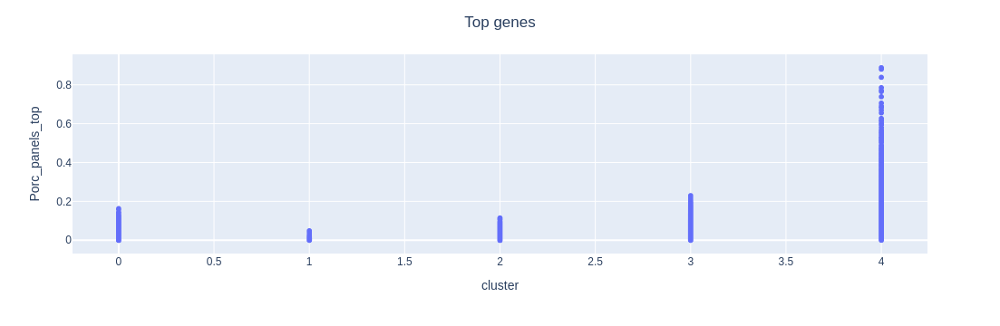

In [91]:
import plotly.express as px
import pandas as pd

stat_tops["Symbol"] = stat_tops.index

fig = px.scatter(stat_tops, x="cluster", y="Porc_panels_top", log_x=False, size_max=100, 
                 hover_data={'Symbol':True
                            })
fig.update_layout(title_text='Top genes', title_x=0.5)
fig.show()

In [92]:
stat_tops["panel_0"] = (gene_disease_matrix.loc[:, gene_disease_matrix.columns != "Cluster"] == 0).sum(axis = 1)

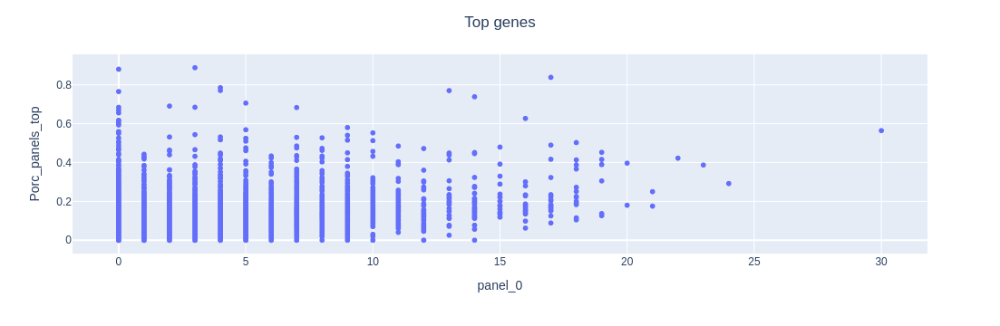

In [93]:
import plotly.express as px
import pandas as pd

stat_tops["Symbol"] = stat_tops.index

fig = px.scatter(stat_tops, x="panel_0", y="Porc_panels_top", log_x=False, size_max=100, 
                 hover_data={'Symbol':True
                            })
fig.update_layout(title_text='Top genes', title_x=0.5)
fig.show()

In [94]:
stat_tops[stat_tops["Porc_panels_top"] >= 0.3]

,N_panels_top,N_panels_nozero,Porc_panels_top,std,std_no_0,median,median_no_0,cluster,Symbol,panel_0
SYMBOL,,,,,,,,,,
CTNNB1,144,204,0.705882,1006.020958,1009.008397,479.0,490.0,4,CTNNB1,5
RAD51,63,201,0.313433,2097.443681,2083.739751,1875.0,2008.0,4,RAD51,8
WRN,61,201,0.303483,2865.909063,2854.027064,2267.0,2360.0,4,WRN,8
MDM2,67,209,0.320574,2061.611430,2061.611430,1826.0,1826.0,4,MDM2,0
ATR,67,202,0.331683,2461.803117,2454.680452,1813.0,1878.0,4,ATR,7
...,...,...,...,...,...,...,...,...,...,...
SOS1,60,197,0.304569,2929.956897,2917.819909,2121.0,2357.0,4,SOS1,12
STK11,65,201,0.323383,1740.434900,1728.283240,1521.0,1559.0,4,STK11,8
TERT,74,190,0.389474,1912.323584,1918.121566,1175.0,1265.5,4,TERT,19


In [95]:
#stat_tops.to_csv('/home/yolanda/tblab/yolanda/GLOWgenes/panelAPP/analysis/data_exploration/stat_tops_vfinal.tsv', sep="\t")

In [88]:
stat_tops.sort_values("Porc_panels_top", ascending=False)

,N_panels_top,N_panels_nozero,Porc_panels_top,std,std_no_0,median,median_no_0,cluster,Symbol,panel_0
SYMBOL,,,,,,,,,,
AKT1,73,206,0.354369,558.402535,559.205508,354.0,362.0,2,AKT1,3
CTNNB1,58,204,0.284314,1006.020958,1009.008397,479.0,490.0,2,CTNNB1,5
TP53,54,195,0.276923,805.235417,810.872924,392.0,432.0,2,TP53,14
MYC,57,209,0.272727,760.938054,760.938054,429.0,429.0,2,MYC,0
EGFR,53,205,0.258537,749.318079,750.578759,442.0,454.0,2,EGFR,4
...,...,...,...,...,...,...,...,...,...,...
CCNJ,0,209,0.000000,4252.639901,4252.639901,14613.0,14613.0,4,CCNJ,0
AMER2,0,209,0.000000,4412.324621,4412.324621,13428.0,13428.0,0,AMER2,0
C19ORF53,0,209,0.000000,4402.082634,4402.082634,14704.0,14704.0,4,C19ORF53,0
